# KAN from scratch : implémenter un réseau de Kolmogorov-Arnold en PyTorch

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/implementer-kan-from-scratch-pytorch/implementer-kan-from-scratch-pytorch.ipynb)

📖 **Le mini-cours complet** : [KAN from scratch : implémentation complète en PyTorch](https://www.monshotdata.com/p/implementer-kan-from-scratch-pytorch)

🧭 **Le cours** : [ML classique et Deep Learning › 2.4 Architectures et entraînement en Deep Learning](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc24)

---

Un réseau de neurones classique apprend des **poids** sur les arêtes et applique une activation fixe (ReLU) sur les nœuds. Un **KAN** inverse l'idée : il apprend l'**activation elle-même**, sous forme d'une courbe (une *spline*) sur chaque arête. Tu vas coder cette idée en une cinquantaine de lignes de PyTorch, puis la comparer au package officiel `pykan`.

**À la fin de ce notebook, tu sauras :**

- comment construire une activation apprenable avec une spline (B-spline) et des points de contrôle ;
- comment empiler ces activations en couches et entraîner le tout comme n'importe quel réseau PyTorch ;
- comment utiliser `pykan` pour visualiser un KAN et voir quelle fonction chaque arête a apprise.


### Avant de lancer

Un **CPU suffit**, l'ensemble s'exécute en moins d'une minute. La première cellule installe `pykan` (plus de versions figées à installer : le code fonctionne avec les versions récentes de PyTorch et NumPy). Les jeux de données sont tirés avec une graine fixe (`random_state=0`, `torch.manual_seed(0)`) : tu retrouves les mêmes résultats à chaque exécution.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, PyTorch 2.x, scikit-learn et pykan 0.2.8.*

## 1. Mise en place

On installe le package officiel `pykan` (utilisé en partie 3), puis on importe PyTorch et scikit-learn.

In [1]:
!pip install -q pykan

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.nn.parameter import Parameter

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

## 2. Un KAN from scratch

On construit le KAN brique par brique : une fonction d'activation, une couche, puis le modèle complet.

### 2.1 L'activation univariée

Chaque arête du réseau porte sa propre fonction `φ(x)`. Ici, `φ` est une **B-spline** : une courbe lisse définie par quelques **points de contrôle** que le réseau apprend par descente de gradient. Plus il y a de points, plus la courbe peut être souple.

In [3]:
class UnivariateActivationFunction(nn.Module):
    def __init__(self, degree=3, control_pts=10):
        super(UnivariateActivationFunction, self).__init__()
        self.degree = degree
        self.control_pts = control_pts

        # Points de contrôle de la B-spline, apprenables
        self.control_points = Parameter(torch.randn(control_pts) * 0.01)

        # Vecteur de nœuds "clampé" : les bornes 0 et 1 sont répétées degree+1 fois,
        # ce qui garantit que la spline couvre tout le domaine [0, 1] sans extrapolation
        knots = torch.cat([
            torch.zeros(degree),
            torch.linspace(0, 1, control_pts - degree + 1),
            torch.ones(degree)
        ])
        self.register_buffer("knots", knots)

        # Poids scalaire, apprenable
        self.w = Parameter(torch.randn(1) * 0.01)

    def forward(self, x):
        silu_x = F.silu(x)
        spline_x = self.compute_bspline(x)
        phi_x = self.w * (silu_x + spline_x)
        return phi_x

    def compute_bspline(self, x):
        return torch.stack([self._bspline_scalar(xi) for xi in x])

    def _bspline_scalar(self, x):
        # Cas limite : borne droite exacte, la spline clampée vaut alors le dernier point de contrôle
        if x >= self.knots[-1]:
            return self.control_points[-1]

        # Algorithme de Cox-de Boor, entièrement en PyTorch : aucun passage par
        # numpy/scipy, donc le gradient remonte correctement jusqu'à control_points
        t, k, n = self.knots, self.degree, self.control_pts
        basis = [((t[i] <= x) & (x < t[i + 1])).float() for i in range(n + k)]

        for d in range(1, k + 1):
            new_basis = []
            for i in range(n + k - d):
                term1 = torch.zeros_like(x)
                term2 = torch.zeros_like(x)
                denom1 = t[i + d] - t[i]
                if denom1 > 0:
                    term1 = (x - t[i]) / denom1 * basis[i]
                denom2 = t[i + d + 1] - t[i + 1]
                if denom2 > 0:
                    term2 = (t[i + d + 1] - x) / denom2 * basis[i + 1]
                new_basis.append(term1 + term2)
            basis = new_basis

        return (self.control_points * torch.stack(basis)).sum()

### 2.2 La couche KAN

Une couche avec `in_features` entrées et `out_features` sorties contient une matrice de fonctions `φ` (une par arête). La sortie `j` est la **somme** des `φ_ij(x_i)` appliquées à chaque entrée `i`. Il n'y a ni produit matriciel de poids, ni activation fixe : tout est dans les courbes.

In [4]:
class KANLayer(nn.Module):
    def __init__(self, in_features, out_features, degree=3, control_pts=10):
        super(KANLayer, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.degree = degree
        self.control_pts = control_pts

        # Initialise la matrice des fonctions univariées
        self.phi_matrix = nn.ModuleList()

        for i in range(in_features):
            row = nn.ModuleList()

            for j in range(out_features):
                row.append(UnivariateActivationFunction(degree, control_pts))

            self.phi_matrix.append(row)

    def forward(self, x):

        # Calcule la sortie à l'aide des fonctions univariées
        out = torch.zeros(x.size(0), self.out_features)
        for i in range(self.in_features):
            for j in range(self.out_features):
                out[:, j] += self.phi_matrix[i][j](x[:, i])

        return out

### 2.3 Le modèle KAN

Deux couches KAN empilées : entrée → couche cachée → sortie.

In [5]:
class KANModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(KANModel, self).__init__()
        self.hidden = KANLayer(input_size, hidden_size)
        self.output = KANLayer(hidden_size, output_size)

    def forward(self, x):
        x = self.hidden(x)
        x = self.output(x)
        return x

### 2.4 Un jeu de données factice

Une régression à deux variables, normalisée entre 0 et 1 (les splines sont définies sur [0, 1]).

In [6]:
# Génère un dataset factice de régression
X, y = make_regression(n_samples=100, n_features=2, noise=0.1, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)
y_train = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_test = scaler_y.transform(y_test.reshape(-1, 1))

# Convertit en tenseurs PyTorch
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

### 2.5 Modèle, perte, optimiseur

In [7]:
torch.manual_seed(0)
model = KANModel(input_size=2, hidden_size=5, output_size=1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

### 2.6 Entraînement

Descente de gradient classique (Adam), 100 itérations. Observe la perte : elle décroît régulièrement vers zéro, ce qui montre que le modèle converge sans difficulté.

In [8]:
# Boucle d'entraînement
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [10/100], Loss: 0.0663
Epoch [20/100], Loss: 0.0164
Epoch [30/100], Loss: 0.0033
Epoch [40/100], Loss: 0.0011
Epoch [50/100], Loss: 0.0005
Epoch [60/100], Loss: 0.0003
Epoch [70/100], Loss: 0.0001
Epoch [80/100], Loss: 0.0001
Epoch [90/100], Loss: 0.0000
Epoch [100/100], Loss: 0.0000


### 2.7 Évaluation sur le jeu de test

La perte de test est du même ordre que la perte d'entraînement : le modèle généralise.

In [9]:
model.eval()

with torch.no_grad():
    predictions = model(X_test)
    test_loss = criterion(predictions, y_test)
    print(f'Test Loss: {test_loss.item():.4f}')

Test Loss: 0.0001


## 3. Le package officiel `pykan`

Notre version est volontairement simplifiée. Le package des auteurs ajoute une partie linéaire résiduelle, des grilles adaptatives, l'élagage et surtout la **visualisation** : on peut voir la forme de chaque fonction apprise.

> Si tu travailles en local, installe `pykan` dans un environnement virtuel dédié, comme expliqué dans le [KAN from scratch : implémentation complète en PyTorch](https://www.monshotdata.com/p/implementer-kan-from-scratch-pytorch).

In [10]:
from kan import *

### 3.1 Créer un jeu de données

On demande à `pykan` de générer 1 000 points pour la fonction connue **f(x₁, x₂) = x₁² + x₂²**. Comme on connaît la formule, on pourra vérifier que le KAN la retrouve.

In [11]:
f = lambda x: x[:,[0]]**2 + x[:,[1]]**2

dataset = create_dataset(f, n_var=2)

dataset['train_input'].shape, dataset['train_label'].shape

(torch.Size([1000, 2]), torch.Size([1000, 1]))

### 3.2 Définir le modèle

`width=[2, 1]` : deux entrées reliées directement à une sortie. `grid=5` et `k=3` : une grille de 5 intervalles et des splines de degré 3.

In [12]:
model = KAN(width=[2,1], grid=5, k=3, seed=0)

checkpoint directory created: ./model
saving model version 0.0


### 3.3 Visualiser le KAN avant l'entraînement

Chaque arête affiche sa fonction `φ`. À l'initialisation, ce sont des courbes lisses quelconques (tirées au hasard). Remarque : il faut faire passer des données une première fois dans le modèle avant d'appeler `plot()`, sinon `pykan` répond `model hasn't seen any data yet`.

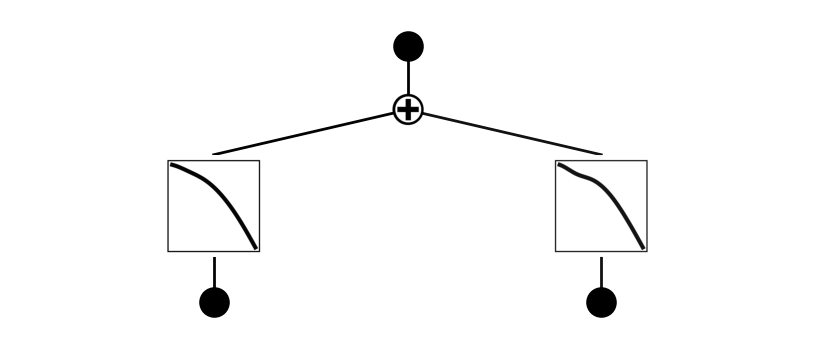

In [13]:
# Visualise le KAN à l'initialisation
model(dataset['train_input']);
model.plot()

### 3.4 Entraîner le KAN

20 pas d'optimisation suffisent : la perte tombe à environ 10⁻⁵.

In [14]:
# Entraîne le modèle
model.fit(dataset, steps=20)

| train_loss: 9.00e-06 | test_loss: 9.54e-06 | reg: 3.91e+00 | : 100%|█| 20/20 [00:04<00:00,  4.33it


saving model version 0.1


{'train_loss': [array(0.03813123, dtype=float32),
  array(0.00822861, dtype=float32),
  array(0.00134763, dtype=float32),
  array(0.00031972, dtype=float32),
  array(0.00010912, dtype=float32),
  array(3.179258e-05, dtype=float32),
  array(9.564231e-06, dtype=float32),
  array(9.021729e-06, dtype=float32),
  array(9.0060275e-06, dtype=float32),
  array(9.0060275e-06, dtype=float32),
  array(9.006324e-06, dtype=float32),
  array(9.006326e-06, dtype=float32),
  array(9.006324e-06, dtype=float32),
  array(9.006324e-06, dtype=float32),
  array(9.006324e-06, dtype=float32),
  array(9.004764e-06, dtype=float32),
  array(9.004779e-06, dtype=float32),
  array(9.004764e-06, dtype=float32),
  array(9.004764e-06, dtype=float32),
  array(9.004762e-06, dtype=float32)],
 'test_loss': [array(0.03768237, dtype=float32),
  array(0.0083153, dtype=float32),
  array(0.00135048, dtype=float32),
  array(0.00032407, dtype=float32),
  array(0.00011018, dtype=float32),
  array(3.2211123e-05, dtype=float32),
  

### 3.5 Visualiser le KAN entraîné

Cette fois, les deux fonctions ont pris la forme d'une **parabole** : le KAN a retrouvé de lui-même le carré de chaque variable. C'est tout l'intérêt de l'architecture : un modèle qui est aussi **lisible**.

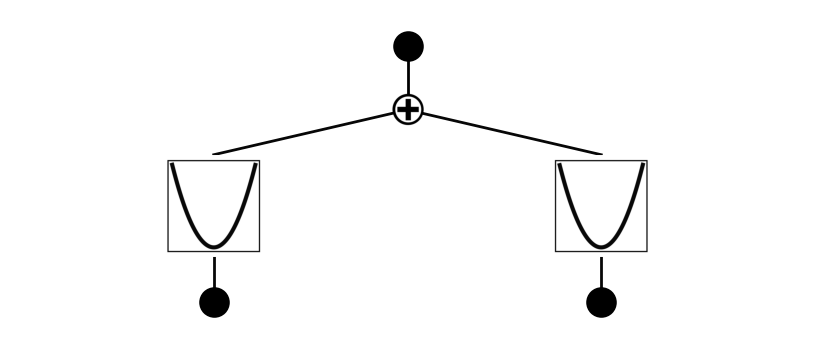

In [15]:
model.plot()

---

## Pour aller plus loin

- [Compression de modèles : un levier clé pour un ML efficace](https://www.monshotdata.com/p/compression-modeles-machine-learning-efficace) — rendre un réseau plus léger et plus rapide
- [Apprentissage Fédéré : Entraîne l'IA, Sécurise les Données](https://www.monshotdata.com/p/guide-pratique-apprentissage-federe) — entraîner un réseau sans centraliser les données